# RoadGuard — YOLO Road Damage Detection
A deep-learning detector to compare with the classical pipeline
(Filtering → Contrast Enhancement → Adaptive Thresholding → Morphology → Boxes).

**Same data as the classical method:** the 5,100 Development and 900 Test images chosen by Member 1
(read from `Processed/Metadata.csv`). Development is split into Train (4,200) and Val (900).
The Test Set is used only once, at the end.

**Runtime:** Runtime → Change runtime type → **T4 GPU**. Run the cells in order.
This notebook is independent: it does not need any earlier cells.

In [ ]:
# Step 1: install YOLO (Ultralytics) and check the GPU.
!pip install -q ultralytics

import torch
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU. Training on CPU will take many hours. Switch to a T4 GPU runtime.')

GPU available: True
GPU: Tesla T4


In [ ]:
# Step 2: paths and settings.
from pathlib import Path
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

from google.colab import drive
if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/RoadGuard_Project')
DATASET_ZIP = PROJECT_DIR / 'Dataset' / 'RDD2022.zip'
METADATA_CSV = PROJECT_DIR / 'Dataset' / 'Processed' / 'Metadata.csv'

YOLO_DATA_DIR = Path('/content/yolo_rdd')          # local disk = fast training
YOLO_RUNS_DIR = PROJECT_DIR / 'YOLO_Runs'          # on Drive = survives disconnects
RUN_NAME = 'yolo11s_rdd_6000'

MODEL_WEIGHTS = 'yolo11s.pt'   # small model: good accuracy, fits a free T4
EPOCHS = 50
IMG_SIZE = 640
BATCH = 16
SEED = 42

for p in [DATASET_ZIP, METADATA_CSV]:
    if not p.exists():
        raise FileNotFoundError(f'Missing: {p}  (check the RoadGuard_Project shortcut in My Drive)')
print('Paths OK')

Paths OK


In [ ]:
# Step 3: reuse Member 1's Development/Test selection and split Development into Train/Val.
meta = pd.read_csv(METADATA_CSV)
meta = meta[['image_id', 'dataset_split', 'original_image_path', 'original_label_path']]

dev_df = meta[meta['dataset_split'] == 'Development'].reset_index(drop=True)
test_df = meta[meta['dataset_split'] == 'Test'].reset_index(drop=True)

train_df, val_df = train_test_split(dev_df, test_size=900, random_state=SEED, shuffle=True)
SPLITS = {'train': train_df, 'val': val_df, 'test': test_df}

for name, df in SPLITS.items():
    print(f'{name:5s}: {len(df)} images')
assert len(train_df) == 4200 and len(val_df) == 900 and len(test_df) == 900
assert set(train_df.image_id).isdisjoint(val_df.image_id)
assert set(dev_df.image_id).isdisjoint(test_df.image_id)

train: 4200 images
val  : 900 images
test : 900 images


In [ ]:
# Step 4: copy the ORIGINAL colour images + labels from the ZIP into YOLO folder format.
# YOLO is pretrained on colour images, so it uses the originals (not the grayscale/enhanced copies).
# Labels are already in YOLO format (class x_center y_center width height, normalized).
# Takes about 5–10 minutes. Re-running skips files that already exist.
with zipfile.ZipFile(DATASET_ZIP, 'r') as z:
    yaml_files = [f for f in z.namelist() if f.lower().endswith(('.yaml', '.yml'))]

    for split, df in SPLITS.items():
        img_dir = YOLO_DATA_DIR / 'images' / split
        lbl_dir = YOLO_DATA_DIR / 'labels' / split
        img_dir.mkdir(parents=True, exist_ok=True)
        lbl_dir.mkdir(parents=True, exist_ok=True)

        for row in tqdm(df.itertuples(index=False), total=len(df), desc=split):
            img_out = img_dir / (row.image_id + Path(row.original_image_path).suffix.lower())
            lbl_out = lbl_dir / (row.image_id + '.txt')
            if not img_out.exists():
                img_out.write_bytes(z.read(row.original_image_path))
            if not lbl_out.exists():
                lbl_out.write_bytes(z.read(row.original_label_path))

    # Class names: use the dataset's own YAML if the ZIP has one.
    CLASS_NAMES = None
    for yf in yaml_files:
        import yaml
        info = yaml.safe_load(z.read(yf))
        if isinstance(info, dict) and 'names' in info:
            names = info['names']
            CLASS_NAMES = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
            print('Class names from', yf, ':', CLASS_NAMES)
            break

if CLASS_NAMES is None:
    # Fallback: generic names for the 5 class IDs (0–4) checked by Member 1.
    CLASS_NAMES = ['class_0', 'class_1', 'class_2', 'class_3', 'class_4']
    print('No YAML found in the ZIP, using generic class names:', CLASS_NAMES)

for split in SPLITS:
    n_img = len(list((YOLO_DATA_DIR / 'images' / split).iterdir()))
    n_lbl = len(list((YOLO_DATA_DIR / 'labels' / split).glob('*.txt')))
    print(f'{split}: {n_img} images, {n_lbl} labels')

train:   0%|          | 0/4200 [00:00<?, ?it/s]

val:   0%|          | 0/900 [00:00<?, ?it/s]

test:   0%|          | 0/900 [00:00<?, ?it/s]

No YAML found in the ZIP, using generic class names: ['class_0', 'class_1', 'class_2', 'class_3', 'class_4']
train: 4200 images, 4200 labels
val: 900 images, 900 labels
test: 900 images, 900 labels


In [ ]:
# Step 5: write the dataset config file that YOLO reads.
data_yaml = YOLO_DATA_DIR / 'data.yaml'
data_yaml.write_text(
    f"path: {YOLO_DATA_DIR}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    f"names: {json.dumps(dict(enumerate(CLASS_NAMES)))}\n"
)
print(data_yaml.read_text())

path: /content/yolo_rdd
train: images/train
val: images/val
test: images/test
names: {"0": "class_0", "1": "class_1", "2": "class_2", "3": "class_3", "4": "class_4"}



In [ ]:
# Step 6: train (about 1 minute per epoch on a T4 → ~50–60 minutes).
# Checkpoints are saved to Drive every epoch. If Colab disconnects, run Steps 1–5 again,
# then this cell: it resumes from the last checkpoint automatically.
from ultralytics import YOLO

last_ckpt = YOLO_RUNS_DIR / RUN_NAME / 'weights' / 'last.pt'

if last_ckpt.exists():
    print('Resuming from', last_ckpt)
    model = YOLO(str(last_ckpt))
    model.train(resume=True)
else:
    model = YOLO(MODEL_WEIGHTS)
    model.train(
        data=str(data_yaml),
        epochs=EPOCHS,
        imgsz=IMG_SIZE,
        batch=BATCH,
        patience=15,            # stop early if Val mAP stops improving
        seed=SEED,
        project=str(YOLO_RUNS_DIR),
        name=RUN_NAME,
        exist_ok=True,
        save_period=1,
        plots=True,
    )

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_rdd/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, free

In [ ]:
# Step 7: official YOLO metrics on the TEST set (used for the first time here).
BEST_WEIGHTS = YOLO_RUNS_DIR / RUN_NAME / 'weights' / 'best.pt'
best_model = YOLO(str(BEST_WEIGHTS))

test_metrics = best_model.val(data=str(data_yaml), split='test', imgsz=IMG_SIZE,
                              project=str(YOLO_RUNS_DIR), name=RUN_NAME + '_test', exist_ok=True)

print(f'Test mAP@0.5      : {test_metrics.box.map50:.4f}')
print(f'Test mAP@0.5:0.95 : {test_metrics.box.map:.4f}')
print(f'Test Precision    : {test_metrics.box.mp:.4f}')
print(f'Test Recall       : {test_metrics.box.mr:.4f}')

per_class = pd.DataFrame({
    'class': [CLASS_NAMES[i] for i in test_metrics.box.ap_class_index],
    'AP@0.5': test_metrics.box.ap50,
})
per_class.round(4)

NameError: name 'YOLO' is not defined

In [ ]:
# Step 7: official YOLO metrics on the TEST set (used for the first time here).
from ultralytics import YOLO

BEST_WEIGHTS = YOLO_RUNS_DIR / RUN_NAME / 'weights' / 'best.pt'
best_model = YOLO(str(BEST_WEIGHTS))

test_metrics = best_model.val(data=str(data_yaml), split='test', imgsz=IMG_SIZE,
                              batch=8, workers=2,
                              project=str(YOLO_RUNS_DIR), name=RUN_NAME + '_test', exist_ok=True)

print(f'Test mAP@0.5      : {test_metrics.box.map50:.4f}')
print(f'Test mAP@0.5:0.95 : {test_metrics.box.map:.4f}')
print(f'Test Precision    : {test_metrics.box.mp:.4f}')
print(f'Test Recall       : {test_metrics.box.mr:.4f}')

per_class = pd.DataFrame({
    'class': [CLASS_NAMES[i] for i in test_metrics.box.ap_class_index],
    'AP@0.5': test_metrics.box.ap50,
})
per_class.round(4)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 40.7±8.9 MB/s, size: 63.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/yolo_rdd/labels/test.cache... 900 images, 279 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 900/900 157.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 113/113 4.5it/s 24.9s
                   all        900       1520      0.561      0.463      0.475      0.232
               class_0        329        649      0.574      0.446      0.464      0.232
               class_1        191        276      0.533      0.406      0.392      0.157
               class_2        191        247       0.63      0.47

,class,AP@0.5
0,class_0,0.4637
1,class_1,0.3918
2,class_2,0.5506
3,class_3,0.6626
4,class_4,0.3064


In [ ]:
# Step 8: same evaluation as the classical method, so the numbers are comparable:
# class-agnostic matching, IoU >= 0.5, one prediction per ground-truth box → TP, FP, FN, P, R, F1.
# The confidence threshold is chosen on VAL (max F1), then applied once to TEST.

def read_gt(label_path):
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().split('\n'):
            v = line.split()
            if len(v) == 5:
                _, xc, yc, w, h = map(float, v)
                boxes.append([xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2])
    return np.array(boxes).reshape(-1, 4)


def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-12)


def count_matches(pred, scores, gt, iou_thr=0.5):
    """Greedy matching, highest-confidence prediction first. Normalized coords (IoU is unchanged)."""
    if len(pred) == 0:
        return 0, 0, len(gt)
    pred = pred[np.argsort(-scores)]
    ious = iou_matrix(pred, gt)
    used = np.zeros(len(gt), dtype=bool)
    tp = 0
    for i in range(len(pred)):
        if len(gt) == 0:
            break
        cand = np.where(~used, ious[i], -1)
        j = int(np.argmax(cand))
        if cand[j] >= iou_thr:
            used[j] = True
            tp += 1
    return tp, len(pred) - tp, len(gt) - tp


def predict_split(split):
    """Run the model once with a low threshold and keep all boxes; thresholds are applied later."""
    img_paths = sorted((YOLO_DATA_DIR / 'images' / split).iterdir())
    out = []
    for r in tqdm(best_model.predict(source=[str(p) for p in img_paths], imgsz=IMG_SIZE, conf=0.01,
                                     stream=True, verbose=False), total=len(img_paths), desc=split):
        stem = Path(r.path).stem
        out.append({
            'stem': stem,
            'pred': r.boxes.xyxyn.cpu().numpy(),
            'score': r.boxes.conf.cpu().numpy(),
            'gt': read_gt(YOLO_DATA_DIR / 'labels' / split / f'{stem}.txt'),
        })
    return out


def evaluate(preds, conf_thr):
    tp = fp = fn = n_pred = 0
    for p in preds:
        keep = p['score'] >= conf_thr
        a, b, c = count_matches(p['pred'][keep], p['score'][keep], p['gt'])
        tp += a; fp += b; fn += c; n_pred += int(keep.sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return dict(conf=conf_thr, TP=tp, FP=fp, FN=fn, precision=precision, recall=recall,
                F1=f1, boxes_per_image=n_pred / len(preds))


VAL_PREDS = predict_split('val')
val_sweep = pd.DataFrame([evaluate(VAL_PREDS, t) for t in np.round(np.arange(0.05, 0.81, 0.05), 2)])
BEST_CONF = float(val_sweep.loc[val_sweep['F1'].idxmax(), 'conf'])
print('Confidence threshold chosen on Val:', BEST_CONF)
display(val_sweep.round(4))

TEST_PREDS = predict_split('test')
yolo_test = evaluate(TEST_PREDS, BEST_CONF)
print('YOLO on TEST (IoU >= 0.5, class-agnostic):')
print(pd.Series(yolo_test).round(4))

val:   0%|          | 0/900 [00:00<?, ?it/s]

In [ ]:
# Step 8: same evaluation as the classical method, so the numbers are comparable:
# class-agnostic matching, IoU >= 0.5 → TP, FP, FN, Precision, Recall, F1.
# The confidence threshold is chosen on VAL (max F1), then applied once to TEST.
# Low-RAM version: predicts ONE image at a time and saves predictions to Drive,
# so if the session crashes, re-running this cell continues from the saved file.
import gc
import pickle
import torch
from ultralytics import YOLO

if 'best_model' not in globals():
    best_model = YOLO(str(YOLO_RUNS_DIR / RUN_NAME / 'weights' / 'best.pt'))

PRED_CACHE_DIR = YOLO_RUNS_DIR / 'predictions_cache'
PRED_CACHE_DIR.mkdir(parents=True, exist_ok=True)


def read_gt(label_path):
    boxes = []
    if label_path.exists():
        for line in label_path.read_text().split('\n'):
            v = line.split()
            if len(v) == 5:
                _, xc, yc, w, h = map(float, v)
                boxes.append([xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2])
    return np.array(boxes, dtype=np.float32).reshape(-1, 4)


def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-12)


def count_matches(pred, scores, gt, iou_thr=0.5):
    """Greedy matching, highest-confidence prediction first. Normalized coords (IoU is unchanged)."""
    if len(pred) == 0:
        return 0, 0, len(gt)
    pred = pred[np.argsort(-scores)]
    ious = iou_matrix(pred, gt)
    used = np.zeros(len(gt), dtype=bool)
    tp = 0
    for i in range(len(pred)):
        if len(gt) == 0:
            break
        cand = np.where(~used, ious[i], -1)
        j = int(np.argmax(cand))
        if cand[j] >= iou_thr:
            used[j] = True
            tp += 1
    return tp, len(pred) - tp, len(gt) - tp


def predict_split(split):
    """Predict each image separately (low RAM) with a low threshold; thresholds are applied later."""
    cache_file = PRED_CACHE_DIR / f'{split}_preds.pkl'
    if cache_file.exists():
        print(f'{split}: loaded saved predictions from {cache_file.name}')
        return pickle.loads(cache_file.read_bytes())

    img_paths = sorted((YOLO_DATA_DIR / 'images' / split).iterdir())
    out = []
    for path in tqdm(img_paths, desc=split):
        r = best_model.predict(source=str(path), imgsz=IMG_SIZE, conf=0.01,
                               max_det=100, verbose=False)[0]
        out.append({
            'stem': path.stem,
            'pred': r.boxes.xyxyn.cpu().numpy().astype(np.float32),
            'score': r.boxes.conf.cpu().numpy().astype(np.float32),
            'gt': read_gt(YOLO_DATA_DIR / 'labels' / split / f'{path.stem}.txt'),
        })
        del r

    cache_file.write_bytes(pickle.dumps(out))
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return out


def evaluate(preds, conf_thr):
    tp = fp = fn = n_pred = 0
    for p in preds:
        keep = p['score'] >= conf_thr
        a, b, c = count_matches(p['pred'][keep], p['score'][keep], p['gt'])
        tp += a; fp += b; fn += c; n_pred += int(keep.sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return dict(conf=conf_thr, TP=tp, FP=fp, FN=fn, precision=precision, recall=recall,
                F1=f1, boxes_per_image=n_pred / len(preds))


VAL_PREDS = predict_split('val')
val_sweep = pd.DataFrame([evaluate(VAL_PREDS, t) for t in np.round(np.arange(0.05, 0.81, 0.05), 2)])
BEST_CONF = float(val_sweep.loc[val_sweep['F1'].idxmax(), 'conf'])
print('Confidence threshold chosen on Val:', BEST_CONF)
display(val_sweep.round(4))

TEST_PREDS = predict_split('test')
yolo_test = evaluate(TEST_PREDS, BEST_CONF)
print('YOLO on TEST (IoU >= 0.5, class-agnostic):')
print(pd.Series(yolo_test).round(4))

val:   0%|          | 0/900 [00:00<?, ?it/s]

Confidence threshold chosen on Val: 0.25


,conf,TP,FP,FN,precision,recall,F1,boxes_per_image
0,0.05,951,2271,459,0.2952,0.6745,0.4106,3.5800
1,0.10,849,1258,561,0.4029,0.6021,0.4828,2.3411
2,0.15,775,865,635,0.4726,0.5496,0.5082,1.8222
3,0.20,705,623,705,0.5309,0.5000,0.5150,1.4756
4,0.25,658,476,752,0.5802,0.4667,0.5173,1.2600
5,0.30,612,361,798,0.6290,0.4340,0.5136,1.0811
6,0.35,546,273,864,0.6667,0.3872,0.4899,0.9100
7,0.40,499,212,911,0.7018,0.3539,0.4705,0.7900
8,0.45,442,151,968,0.7454,0.3135,0.4413,0.6589
9,0.50,366,96,1044,0.7922,0.2596,0.3910,0.5133


test:   0%|          | 0/900 [00:00<?, ?it/s]

YOLO on TEST (IoU >= 0.5, class-agnostic):
conf                 0.2500
TP                 738.0000
FP                 498.0000
FN                 782.0000
precision            0.5971
recall               0.4855
F1                   0.5356
boxes_per_image      1.3733
dtype: float64


In [ ]:
# Step 9: comparison table for the report.
# The classical numbers below are Member 4's Development-validation results (F1@0.5 = 0.0432).
# Replace them with Member 5's TEST-set numbers when available, so both methods use the same images.
CLASSICAL = dict(method='Classical (Adaptive Threshold + Morphology)', TP=360, FP=9152, FN=6778,
                 precision=0.0378, recall=0.0504, F1=0.0432, boxes_per_image=2.32)

comparison = pd.DataFrame([
    CLASSICAL,
    dict(method=f'YOLO ({Path(MODEL_WEIGHTS).stem}, conf={BEST_CONF})',
         **{k: yolo_test[k] for k in ['TP', 'FP', 'FN', 'precision', 'recall', 'F1', 'boxes_per_image']}),
])
display(comparison.round(4))

,method,TP,FP,FN,precision,recall,F1,boxes_per_image
0,Classical (Adaptive Threshold + Morphology),360,9152,6778,0.0378,0.0504,0.0432,2.3200
1,"YOLO (yolo11s, conf=0.25)",738,498,782,0.5971,0.4855,0.5356,1.3733


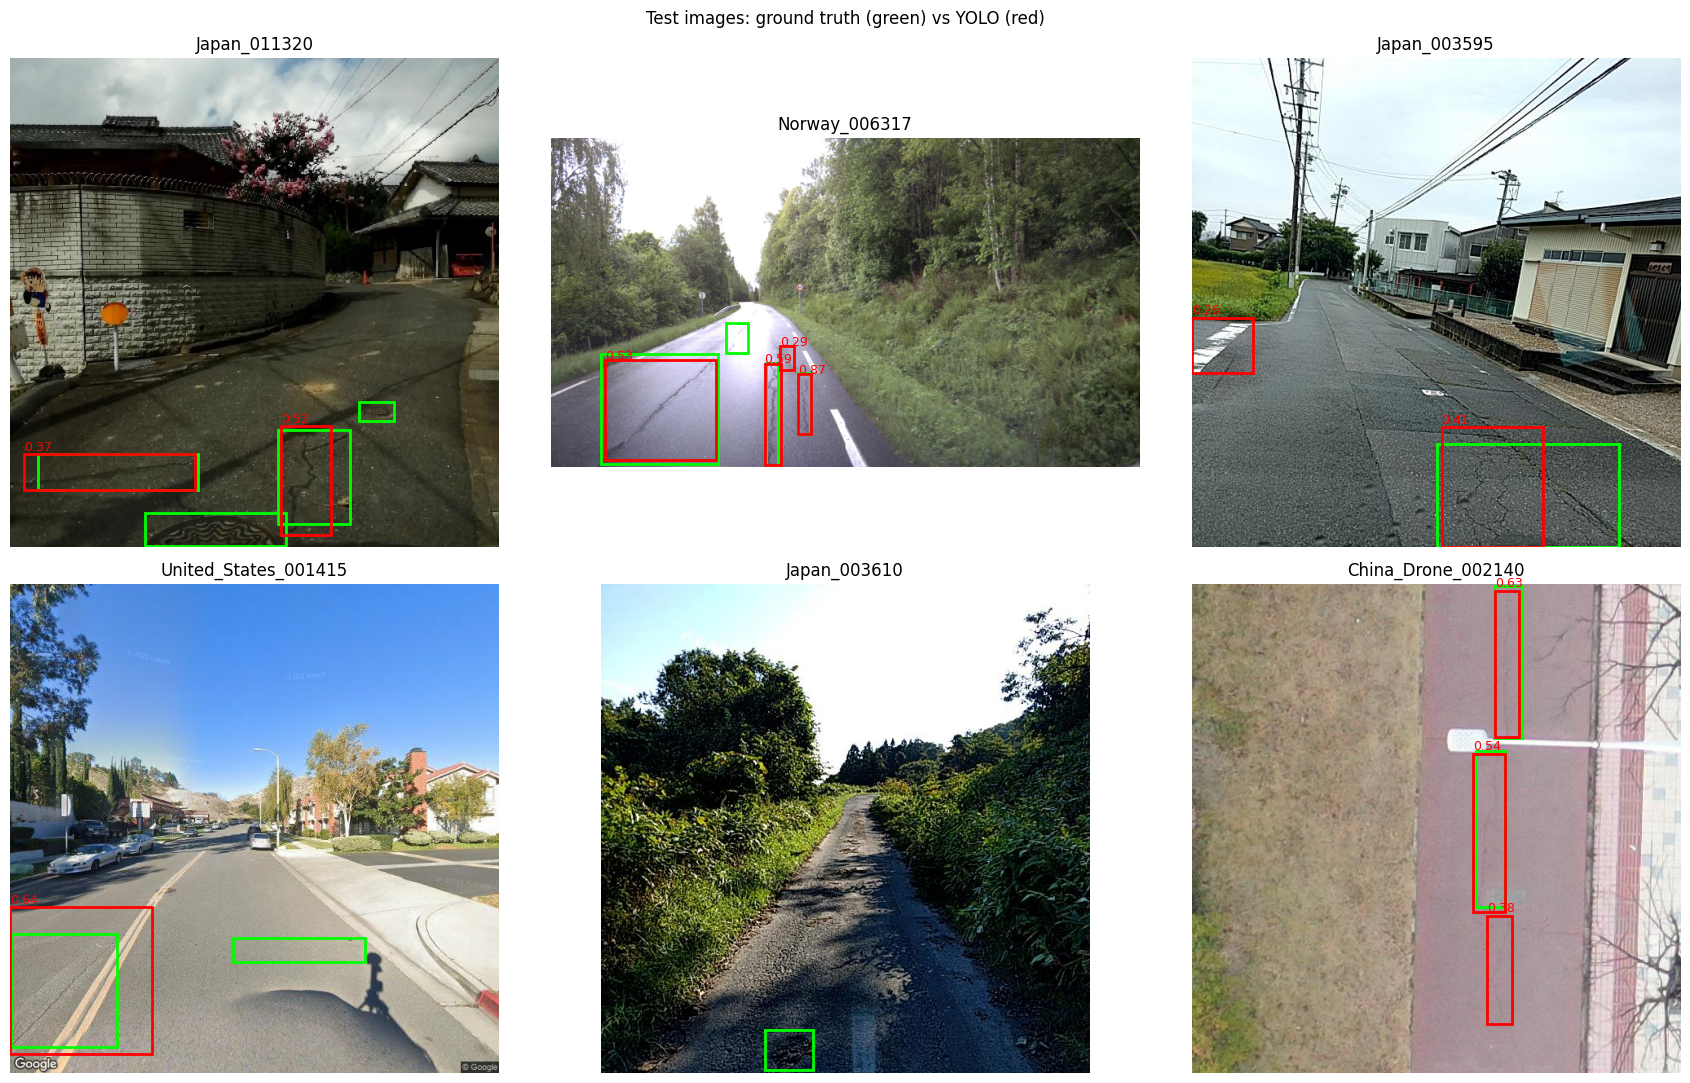

In [ ]:
# Step 10: visual examples on TEST — ground truth (green) vs YOLO predictions (red).
import cv2

rng = np.random.default_rng(SEED)
with_gt = [p for p in TEST_PREDS if len(p['gt']) > 0]
examples = [with_gt[i] for i in rng.choice(len(with_gt), 6, replace=False)]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, p in zip(axes.ravel(), examples):
    img_path = next((YOLO_DATA_DIR / 'images' / 'test').glob(p['stem'] + '.*'))
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    ax.imshow(img)
    for x1, y1, x2, y2 in p['gt']:
        ax.add_patch(patches.Rectangle((x1 * w, y1 * h), (x2 - x1) * w, (y2 - y1) * h,
                                       fill=False, edgecolor='lime', linewidth=2))
    keep = p['score'] >= BEST_CONF
    for (x1, y1, x2, y2), s in zip(p['pred'][keep], p['score'][keep]):
        ax.add_patch(patches.Rectangle((x1 * w, y1 * h), (x2 - x1) * w, (y2 - y1) * h,
                                       fill=False, edgecolor='red', linewidth=2))
        ax.text(x1 * w, y1 * h - 4, f'{s:.2f}', color='red', fontsize=9)
    ax.set_title(p['stem'])
    ax.axis('off')
plt.suptitle('Test images: ground truth (green) vs YOLO (red)')
plt.tight_layout()

FIG_DIR = YOLO_RUNS_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIG_DIR / 'yolo_test_examples.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Step 11: save results to Drive for the team and the report.
val_sweep.to_csv(YOLO_RUNS_DIR / 'yolo_val_threshold_sweep.csv', index=False)
comparison.to_csv(YOLO_RUNS_DIR / 'classical_vs_yolo.csv', index=False)
per_class.to_csv(YOLO_RUNS_DIR / 'yolo_test_per_class_ap50.csv', index=False)
(YOLO_RUNS_DIR / 'yolo_summary.json').write_text(json.dumps({
    'model': MODEL_WEIGHTS, 'epochs_requested': EPOCHS, 'img_size': IMG_SIZE, 'batch': BATCH,
    'train_images': len(train_df), 'val_images': len(val_df), 'test_images': len(test_df),
    'class_names': CLASS_NAMES,
    'test_mAP50': float(test_metrics.box.map50), 'test_mAP50_95': float(test_metrics.box.map),
    'confidence_threshold_from_val': BEST_CONF,
    'test_class_agnostic_iou50': {k: float(v) for k, v in yolo_test.items()},
}, indent=2))
print('Saved to', YOLO_RUNS_DIR)
print([p.name for p in YOLO_RUNS_DIR.iterdir()])

Saved to /content/drive/MyDrive/RoadGuard_Project/YOLO_Runs
['yolo11s_rdd_6000', 'yolo11s_rdd_6000_test', 'predictions_cache', 'figures', 'yolo_val_threshold_sweep.csv', 'classical_vs_yolo.csv', 'yolo_test_per_class_ap50.csv', 'yolo_summary.json']


In [ ]:
# Update the Classical vs YOLO comparison table (no training, no GPU, no image copying).
# Uses the YOLO predictions already saved on Drive in Step 8.
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
from google.colab import drive

if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')

YOLO_RUNS_DIR = Path('/content/drive/MyDrive/RoadGuard_Project/YOLO_Runs')
PRED_CACHE_DIR = YOLO_RUNS_DIR / 'predictions_cache'

# ---- 1) Final classical results (Member 5, TEST set, final full method) ----
CLASSICAL = dict(
    method='Classical (Improved Adaptive + Morphology + Canny)',
    TP=89, FP=2424, FN=1431,
    precision=0.0354, recall=0.0586, F1=0.0441,
    boxes_per_image=2.792,
)
CLASSICAL_SET = 'Test (900 images)'


# ---- 2) YOLO results from the saved predictions (same rules as Step 8) ----
def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-12)


def count_matches(pred, scores, gt, iou_thr=0.5):
    if len(pred) == 0:
        return 0, 0, len(gt)
    pred = pred[np.argsort(-scores)]
    ious = iou_matrix(pred, gt)
    used = np.zeros(len(gt), dtype=bool)
    tp = 0
    for i in range(len(pred)):
        if len(gt) == 0:
            break
        cand = np.where(~used, ious[i], -1)
        j = int(np.argmax(cand))
        if cand[j] >= iou_thr:
            used[j] = True
            tp += 1
    return tp, len(pred) - tp, len(gt) - tp


def evaluate(preds, conf_thr):
    tp = fp = fn = n_pred = 0
    for p in preds:
        keep = p['score'] >= conf_thr
        a, b, c = count_matches(p['pred'][keep], p['score'][keep], p['gt'])
        tp += a; fp += b; fn += c; n_pred += int(keep.sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return dict(conf=conf_thr, TP=tp, FP=fp, FN=fn, precision=precision, recall=recall,
                F1=f1, boxes_per_image=n_pred / len(preds))


VAL_PREDS = pickle.loads((PRED_CACHE_DIR / 'val_preds.pkl').read_bytes())
TEST_PREDS = pickle.loads((PRED_CACHE_DIR / 'test_preds.pkl').read_bytes())
val_sweep = pd.DataFrame([evaluate(VAL_PREDS, t) for t in np.round(np.arange(0.05, 0.81, 0.05), 2)])
BEST_CONF = float(val_sweep.loc[val_sweep['F1'].idxmax(), 'conf'])
yolo_test = evaluate(TEST_PREDS, BEST_CONF)

# ---- 3) Build and save the table ----
cols = ['TP', 'FP', 'FN', 'precision', 'recall', 'F1', 'boxes_per_image']
comparison = pd.DataFrame([
    {**{k: CLASSICAL[k] for k in ['method'] + cols}, 'evaluated_on': CLASSICAL_SET},
    {'method': f'YOLO (yolo11s, conf={BEST_CONF})', **{k: yolo_test[k] for k in cols},
     'evaluated_on': 'Test (900 images)'},
])
comparison.to_csv(YOLO_RUNS_DIR / 'classical_vs_yolo.csv', index=False)
print('Saved:', YOLO_RUNS_DIR / 'classical_vs_yolo.csv')
display(comparison.round(4))

Mounted at /content/drive
Saved: /content/drive/MyDrive/RoadGuard_Project/YOLO_Runs/classical_vs_yolo.csv


,method,TP,FP,FN,precision,recall,F1,boxes_per_image,evaluated_on
0,Classical (Improved Adaptive + Morphology + Ca...,89,2424,1431,0.0354,0.0586,0.0441,2.7920,Test (900 images)
1,"YOLO (yolo11s, conf=0.25)",738,498,782,0.5971,0.4855,0.5356,1.3733,Test (900 images)
